<a href="https://colab.research.google.com/github/rhnavarreteing-hash/Unidad1-MachineLearning-Equipo3/blob/main/Red.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MODELOS DE APRENDIZAJE**

## **UNIDAD 4**


## Deep Learning — Red neuronal completamente conectada para reconocer señas ASL

**Objetivo:** entrenar desde cero, con NumPy, una red neuronal que clasifique imágenes de 28 × 28 píxeles correspondientes a 24 letras del alfabeto manual estadounidense (sin J ni Z, que requieren movimiento).

**Procedimiento:** cargar los archivos `sign_mnist_train.csv` y `sign_mnist_valid.csv`, separar validación/prueba, normalizar, codificar etiquetas, implementar las capas y la retropropagación, entrenar, evaluar y analizar los resultados.

**Nota:** el conjunto de datos utilizado es **Sign Language MNIST**, que contiene imágenes de manos de 28 × 28 píxeles; no es el conjunto de imágenes fotográficas ASL Alphabet mencionado en algunos enlaces de referencia.

--------------------------------------------------------------------------
#**INTRODUCTION**

American Sign Language (ASL) is a visual and gestural system primarily used by deaf and hard-of-hearing individuals. It uses a combination of hand signs, facial expressions, body movements, and hand positioning to convey meanings, ideas, and emotions. Its origins date back to the 19th century, when the first school for the deaf in the United States, known as the "Hartford School for the Deaf," was founded in 1817.

Today, ASL is recognized as a legitimate language with its own grammar and structure, and is used by the deaf community in the United States and other parts of the world, promoting the cultural identity of deaf individuals and inclusion in society.

In this notebook, we will implement a Fully Connected Network for the Kaggle ASL Dataset.

--------------------------------------------------------------------------

##**Importing necessary libraries**

In [ ]:
import numpy as np #manejo de arreglos, matrices
import string #utiles para etiquetas de texto
import pandas as pd #lectura y manipulacion de CSV
import matplotlib.pyplot as plt #graficar
import cv2 as cv #procesamiento de imagenes
import os #manejo de rutas de archivos

#recarga automaticamente modulos
%load_ext autoreload
%autoreload 2
#################################
#muestra graficas directamente en el notebook
%matplotlib inline

from google.colab import drive
import sys

In [ ]:
# Montar Google Drive (ejecutar en Google Colab).
drive.mount('/content/drive')
print('Google Drive conectado. Continúa con la lectura de los CSV.')

In [ ]:
# Cambia esta ruta si guardaste los CSV en otra carpeta de Google Drive.
DATA_PATH = '/content/drive/MyDrive/Escuela/Aprendizaje Profundo/asl_data'
train_csv = os.path.join(DATA_PATH, 'sign_mnist_train.csv')
valid_csv = os.path.join(DATA_PATH, 'sign_mnist_valid.csv')

for ruta in (train_csv, valid_csv):
    if not os.path.isfile(ruta):
        raise FileNotFoundError(
            f'No se encontró {ruta}. Sube los dos CSV a esa carpeta '
            'o modifica DATA_PATH con la ruta donde los guardaste.'
        )

train_df = pd.read_csv(train_csv)
valid_df = pd.read_csv(valid_csv)
print('Datos cargados:', train_df.shape, valid_df.shape)

In [ ]:
#Now we want to see the first 5 rows of the train set
train_df.head()

In [ ]:
#Now we want to see the first 5 rows of the validation set
valid_df.head()

## **Import Images**

In [ ]:
#Now we will get the output which we will store in the variable y_train and y_valid, the output is going to be the column "label" from each df.
y_train = np.array(train_df['label'])
y_val = np.array(valid_df['label'])

del train_df['label']
del valid_df['label']

x_train = train_df.values.astype(np.float32)
x_val = valid_df.values.astype(np.float32)

In [ ]:
#We see that the output data for the validation set has 7172 rows.
y_val.shape

The code below takes sample indices and randomly combines them to create a dataset where classes can be distributed between the two datasets (aiming to avoid duplicates). This allows the data to be divided into validation and testing sets using the np.split function from the numpy framework, ensuring each set contains 50% of the data.

PROCESAMIENTO

In [ ]:
#This is the function split_val_test to split the data from the validation set into validation and test sets.
def split_val_test(x, y, pct=0.5, shuffle=True):
    '''

    TOMA EL CONJUNTO X_VAL Y LO SEPARA EN :
    - VALIDACION (para ajustar el modelo)
    - PRUEBA (para evaluar el modelo final)

    Divide a validation dataset into two subsets: validation and test.

    param x: array or list of features from the dataset (Caracteristicas (IMAGENES))
    param y: array or list of labels from the dataset (ETIQUETAS (CLASES))
    param pct: PORCENTAJE PARA EL CONJUNTO DE VALIDACION
    param shuffle: PARA MEZCLAR LOS DATOS ANTES

    return: two sets (x_val, y_val) for validation, and (x_test, y_test) for testing
    '''

    # Combine x and y into one structure for easy splitting
    # UNE LAS ENTRADAS X Y ETIQUETAS Y EN UNA SOLA MATRIZ
    data = np.column_stack((x, y))

    # Shuffle the data if required
    #EL MEZCLAR ALEATORIAMENTE LOS DATOS EVITA SESGOS COMO: datos ordenados por clase o entrenamiento poce generalizable
    if shuffle:
      np.random.shuffle(data)

    # Determine the index for splitting the data
    #divide en 2 el conjunto (mitad para validacion y mitadl para prueba)
    split_index = int(len(data) * pct)

    # Split the data into validation and test sets
    val_data = data[:split_index]   # The first pct data points are fot the val set
    test_data = data[split_index:]  # The rest is for the test set

    # Separate features (x) and labels (y) for the validation and test sets
    x_val, y_val = val_data[:, :-1], val_data[:, -1].astype(int)
    x_test, y_test = test_data[:, :-1], test_data[:, -1].astype(int)

    return x_val, y_val, x_test, y_test

In [ ]:
# Separación reproducible: 50% validación, 50% prueba.
np.random.seed(42)
x_val, y_val, x_test, y_test = split_val_test(x_val, y_val)

# Las etiquetas originales van de 0 a 24, pero no existe la clase 9 (J).
# Las comprimimos a 0..23 para obtener 24 salidas válidas en softmax.
def compact_labels(y):
    y = np.asarray(y, dtype=np.int64)
    if np.any(y == 9) or np.any((y < 0) | (y > 24)):
        raise ValueError('Se esperaban etiquetas ASL de 0 a 24, excluyendo 9 (J).')
    return np.where(y > 9, y - 1, y)

y_train = compact_labels(y_train)
y_val = compact_labels(y_val)
y_test = compact_labels(y_test)
print('Etiquetas codificadas:', np.unique(y_train))

In [ ]:
# Output the results to confirm that the function splitted correctly
print("Validation set (x_val_split, y_val_split):")
print(x_val.shape, y_val.shape)

print("\nTest set (x_test_split, y_test_split):")
print(x_test.shape, y_test.shape)

In [ ]:
### The following store a list of the alphabet ascii lowercase into the variable "alphabet"

alphabet=list(string.ascii_lowercase)
#We remove the letters 'j' and 'z' because in sign language this letters need motion, and since we are using images, we can't really know the 'j' and 'z'.
alphabet.remove('j')
alphabet.remove('z')
print(len(alphabet))

--------------------------------------------------------------------------

## **Normalization**

Normalization is a data preprocessing process that involves adjusting the values of the features in a dataset to have a common scale, usually within a specified range. This procedure helps machine learning models, such as neural networks, to function more efficiently and stably. It is a crucial step, as it ensures that the features have similar scales, making it easier for optimization algorithms, such as gradient descent, to work effectively.

The main purpose of normalization is to prevent certain features with larger or smaller values from disproportionately influencing the model, especially in algorithms that rely on distances, such as neural networks or regression methods.

Next, normalization will be applied to the training, validation, and test

-------------------------------------------------------------------------

In [ ]:
# we defined a function to normalize the data
def normalize_data(x_mean, x_std, x_data):
  '''
  Normalize the input data based on provided mean and standard derivation

  param x_mean: mean of the input data
  param x_std: standard deviation of the input data
  param x_data: input data to be normalized

  return: normalized data
  '''
  return (x_data - x_mean) / x_std

In [ ]:
# Usar exclusivamente estadísticas del entrenamiento evita filtrar datos de validación/prueba.
x_mean = x_train.mean()
x_std = x_train.std()
if x_std == 0:
    raise ValueError('La desviación estándar es 0: revisa los datos de entrada.')
x_train = normalize_data(x_mean, x_std, x_train).astype(np.float32)
x_val = normalize_data(x_mean, x_std, x_val).astype(np.float32)
x_test = normalize_data(x_mean, x_std, x_test).astype(np.float32)

Mean close to 0 ensures that the data is centered around zero, which helps the model converge faster because it avoids large gradients that can slow down learning or destabilize training.\
Standard deviation close to 1 ensures that the data is scaled consistently, which prevents some features from dominating due to their larger numerical ranges.

In [ ]:
# Check the functions works, we need the mean to be really close to 0 and the std dev to be close to 1.
x_train.mean(), x_train.std()

La normalización utiliza la media y desviación estándar del conjunto de entrenamiento. La media normalizada debe estar cerca de **0** y la desviación estándar cerca de **1**. Los valores exactos se comprueban en la celda anterior.

##**Plot samples**

The first function uses the resized pixel values with the imshow instance to graph unique images.

A function that takes pixel values for unique classes (24 in this case) and creates images for each class using subplots.

In [ ]:
#We defined a function to plot the images,
def plot_image(image):
    plt.figure(figsize=(12,6)) # Create figure
    plt.imshow(image.reshape(28,28), cmap='gray')   # Reshape the image data to a 2D array (28x28)
    plt.axis('off') #Hide axes
    plt.show()

In [ ]:
#For this part we based the code from the activity 1a, and we use the rnd_index variable to store in it a random index taken from the training set.
rnd_index = np.random.randint(len(y_train))   # Select a random image for train data set

print(f'La imagen mostrada representa la letra: {alphabet[y_train[rnd_index]]}')

plot_image(x_train[rnd_index])

In [ ]:
# Una imagen representativa por cada clase original.
# Si el entorno se reinició, se vuelve a definir la ruta del CSV
# (debe coincidir con DATA_PATH de la celda de carga de datos).
if 'train_csv' not in globals():
    DATA_PATH = '/content/drive/MyDrive/Escuela/Aprendizaje Profundo/asl_data'
    train_csv = os.path.join(DATA_PATH, 'sign_mnist_train.csv')
    print('Aviso: train_csv no estaba definido. Ejecuta el notebook desde el inicio '
          '(Entorno de ejecución > Ejecutar todas) para que existan x_train, y_train, etc.')

df_plot = pd.read_csv(train_csv)
df_plot = df_plot.drop_duplicates(subset=['label']).sort_values('label').reset_index(drop=True)
x_plot = df_plot.drop(columns=['label'])

def plot_sample_images():
    plt.figure(figsize=(16, 9))
    for i in range(len(df_plot)):
        plt.subplot(4, 6, i + 1)
        img = x_plot.iloc[i].values.reshape(28, 28)
        original_label = int(df_plot.loc[i, 'label'])
        plt.imshow(img, cmap='gray')
        plt.title(string.ascii_lowercase[original_label].upper())
        plt.axis('off')
    plt.tight_layout()
    plt.show()

plot_sample_images()

---
## Ecuaciones del modelo

Para tres capas ocultas con activación ReLU:

\[Z_1=W_1X+b_1,\quad A_1=\mathrm{ReLU}(Z_1)\]
\[Z_2=W_2A_1+b_2,\quad A_2=\mathrm{ReLU}(Z_2)\]
\[Z_3=W_3A_2+b_3,\quad A_3=\mathrm{ReLU}(Z_3)\]
\[Z_4=W_4A_3+b_4\]

Softmax transforma las puntuaciones de salida en probabilidades:

\[p_k=\frac{e^{z_k-\max(z)}}{\sum_j e^{z_j-\max(z)}}\]

La función de pérdida es la entropía cruzada promedio:

\[L=-\frac{1}{m}\sum_{i=1}^{m}\log p_{y_i}^{(i)}\]

En retropropagación se calculan gradientes y se actualizan pesos y sesgos mediante descenso de gradiente.

# **Additional Functions**

# batch size

#8
#16
#32
#128
#512
#....

_________________________________________________________________________
## **Mini-Batches**

Mini-batches are small, randomly selected subsets of the dataset that are used during training in machine learning.

Mini-batches allow data to be loaded more efficiently into memory, making it possible to work with large datasets without exhausting memory. It is also important to mention that in each iteration, the calculated gradient is not the same due to the differences between mini-batches, helping the model avoid overfitting to the training data.

Instead of using the entire dataset at once (batch gradient descent) or a single sample (stochastic gradient descent), mini-batches strike a balance by processing small, manageable chunks of data in each training step.

Training and evaluating images effectively, both in computer vision and other Machine Learning and Deep Learning tasks, is best achieved through batches. By processing sections of the dataset in each epoch, the evaluation is conducted, leading to a more optimized training process.

__________________________________________________________________________

In [ ]:
#Here we defined from the activite 1a, the minibatches function
def create_minibatches(mb_size, x, y, shuffle=True):
  '''
  Create mini-batches from input data.

  x muestras 784
  y muestras 1

  Args:
      mb_size (int): Size of each mini-batch.
      x (numpy.ndarray): Input data (features), where each row represents a sample.
      y (numpy.ndarray): Target data (labels), where each row corresponds to the label of the respective sample in `x`.
      shuffle (bool, optional): If True, shuffle the dataset before splitting into mini-batches. Default is True.

  Returns:
      generator: A generator yielding tuples of (mini_batch_x, mini_batch_y) for each mini-batch.
  '''

  # Ensure that the number of samples in x and y ins the same
  assert x.shape[0] == y.shape[0], 'Las dimensiones de x e y no son compatibles'

  # Total number of samples in the dataset
  total_data = x.shape[0]

  # Suffle the data if requested
  if shuffle:
    indexes = np.arange(total_data)   # Create an array of sample indices
    np.random.shuffle(indexes)        # Randomly suffle the indices
    x = x[indexes]                    # Reorder x based on the suffled indices
    y = y[indexes]                    # Reorder y based on the suffled indices

  # Create and return a generator for mini-batches
  return ((x[i:i+mb_size], y[i:i+mb_size])          # Slices for the current mini-batch
          for i in range(0, total_data, mb_size))   # Iterate in steps of mb_size

## **Our Linear, ReLU and Sequential class**

In [ ]:
#Also from the youtube videos and the code from activity 1a, we defined the class np_tensor, which allows us to use it as the existing np.ndarray class, but with the advantage that
#using np_tensor class we can create our own parameters for example to calculate the gradients and use ".grad" later
class np_tensor(np.ndarray): pass

---------------------------------------------------------------

## **Linear class**

The linear class is a basic function used to compute weights and bias for linearly separable problems. It is similar to the perceptron but demonstrates the step-by-step matrix operations within the numpy framework.





## **Kaiming He initalization**

He initialization is a method for initializing the weights in a deep neural network. It is primarily used to address common issues such as gradient vanishing and exploding gradients. This initialization is particularly useful when using ReLU activation functions (or ReLU variants) in neural networks.

Its purpose is to prevent the gradients from becoming too small (vanishing) or too large during the propagation process, keeping the gradients within an appropriate scale, allowing the model to train stably. It is also important to mention that it leads to faster optimization since the weights are better distributed, allowing the model to learn more quickly.

We corrected the code that Dr gave us.

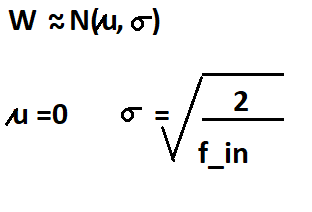



He initialization is effective when the activation function is a ReLU function.

El factor raiz cuadrada de (2/input_size) asegura que los valores iniciales estén dentro de un rango razonable.

---

In [ ]:
#Here we created the class linear, using the __init__ we automatically call an instance of a class, we can
#create instances of the class with different dimensions for different layers.
class Linear():

  def __init__(self, input_size, output_size):
    '''
    Initialize parameters using Kaiming He initialization.

    Args:
        input_size (int): Number of input features (size of the input vector).
        output_size (int): Number of output features (size of the output vector).
    '''

    # Kaiming He initialization for weights
    self.W = (np.random.randn(output_size, input_size) * np.sqrt(2/input_size)).view(np_tensor)

    # Bias initialization (Usuarlly zeros)
    self.b = (np.zeros((output_size, 1))).view(np_tensor)

#For the forward function we will use __call__ method, which allows the object to behave like a function, enabling integration
#and automatically passes from the first layer to the next one
  def __call__(self, X):
    '''
    Forward pass for the linear layer.

    Args:
        X (np.ndarray): Input data of shap (batch_size, input_size).

    Returns:
        np.ndarray: Output of the linear transformation, shape (batch_size, output_size).
    '''
    Z = self.W @ X + self.b
    return Z

#We defined a function for the backpropagation method, here we need X which is our input, and Z which is our output, and we want to start getting
#our gradients.
  def backward(self, X, Z):
    '''
    Backward passs for the linear layer.
    Computes gradients with respect to the input, weights, and bias

    Args:
        X (np.ndarray): Input data of shape (batch_size, input_size).
        Z (np.ndarray): Output of the layer from the forward pass.
    '''

    # Gradient of the input (propagated backward)
    X.grad = self.W.T @ Z.grad

    # Gradient of the weights
    self.W.grad = Z.grad @ X.T

    # Gradient of the bias (sum over batch axis)
    self.b.grad = np.sum(Z.grad, axis=1, keepdims=True)

--------------------------------------------------------------------------

## **ReLU class**

ReLU is a simple, efficient, and effective activation function that improves computational efficiency, helps mitigate gradient vanishing, and enables faster learning. This function converts only negative values to zero, while positive values retain their value, introducing non-linearity and allowing the network to learn complex patterns and perform classification tasks.

It is important to mention that neural networks require non-linear functions to learn complex representations of data, as using only linear functions would prevent the neural network from modeling more complex relationships between inputs and outputs.

Implements the ReLU (Rectified Linear Unit) activation function.
    
The ReLU function is defined as:

    ReLU(Z) = max(0, Z)

It is one of the most commonly used activation functions in deep learning, as it helps to introduce non-linearity while being computationally efficient.


----------------------------------------------------------------------

In [ ]:
#Here we define the Rectified Linear Unit Class to ensure non-linearity in our model
class ReLU():

  #We defined a forward function, using the method of __call__ to automatically run the forward pass, and we need the parameters self, and Z which is our output.
  def __call__(self, Z):
    '''
    Forward pass of the ReLU activation function.

    Args:
        Z (np.ndarray): Input tensor, typically the output of a linear layer.

    Returns:
        np.ndarray: Output tensor after applying the ReLU activation function.
    '''

    return np.maximum(0, Z)

  #Our backward function, works exactly the same,  to get the gradients of the loss function with respect to Z.
  def backward(self, Z, A):
    '''
    Backward pass of the ReLU activation function.

    Compute the gradient of the loss with respect to the input Z,
    based on the gradient of the output A.

    Args:
        Z (np.ndarray): Input tensor, typically the output of a linear layer.
        A (np.ndarray): Output tensor after applying the ReLU activation function.
    '''

    # Copy the gradient from A (output) to Z (input)
    Z.grad = A.grad.copy()

    # Set gradients to 0 where Z <= 0 (ReLU is inactive for negative inputs)
    Z.grad[Z <= 0] = 0

--------------------------------------------------------------------------

##**Sequential class**

The Sequential class instance enables the integration of functions representing network neurons and their respective activation functions in a sequential manner. This facilitates the generation of various matrix calculations, updates, and predictions necessary for training processes in multilayer neural networks.

--------------------------------------------------------------------------

In [ ]:
#Here the sequential_layers class, is created to run the data through the Linear class and the ReLU class:
class Sequential_layers():

  #We create the __init__ to automatically initialize the sequence.
  def __init__(self, layers):
    '''
    Initialize the sequential model.

    Args:
        layers (list): List of layers to be stacked in the sequential model.
    '''

    # Store the layers
    self.layers = layers

    # Placeholder for input data (stores the initial layer)
    self.x = None

    # Directionary to store intermediate outputs for each layer
    self.outputs = {}

#The _call__ function works as the forward method for the layers
  def __call__(self, X):
    '''
    Perform the forward pass through all layers.

    Args:
        X (np.ndarray): Input data of shape (input_size, batch_size).

    Returns:
        np.ndarray: The final output of the network (scores for classification).
    '''

    # Store the initial input
    self.x = X

    # Save the input as the output of "layer 0"
    self.outputs['l0'] = self.x

    # Iterate through all layers and perform forward propagation
    for i, layer in enumerate(self.layers, 1):
      self.x = layer(self.x)    # Pass the output of the previous layer to the next

      self.outputs['l' + str(i)] = self.x   # Store the output for this layer

    return self.x   # Retun the final output

#The backward function helps us to calculate the gradients.
  def backward(self):
    '''
    Perform the backward pass through all layers (in reverse order).

    Uses the stored outputs to calculate gradients for each layer.
    '''

    # Iterate over layers in reverse order
    for i in reversed(range(len(self.layers))):

      # Compute gradients for each layer based on the outputs of the current and next layer
      self.layers[i].backward(self.outputs['l' + str(i)], self.outputs['l' + str(i + 1)])

#Finally the update function we created, will take the result from the backward function and update the values for w and b, based on the learning rate.
  def update(self, learning_rate=1e-3):
    '''
    Update the parameters of all layers using gradient descent.

    Args:
        learning_rate (float, optional): Learning rate for gradient descent. Default is 1e-3.
    '''

    # Iterate through all layers and update their parameters
    for layer in self.layers:

      # Skip activation layers (ReLU does not have parameters to update)
      if isinstance(layer, ReLU): continue

      # Update weights and biases using gradients descent
      layer.W = layer.W - learning_rate * layer.W.grad
      layer.b = layer.b - learning_rate * layer.b.grad

#Here we define the predict function, to make the predictions using the trained model
  def predict(self, X):
    '''
    Make predictions using the trained model.

    Args:
        X (np.ndarray): Input data of shape (input_size, batch_size).

    Returns:
        np.ndarray: Predicted scores for each class.
    '''

    return np.argmax(self.__call__(X), axis=0)


--------------------------------------------------------------------------

## **Cost Function**

The cost function is a measure used to quantify the error of a machine learning model during the training process. Its purpose is to indicate how well or poorly the model is predicting the outcomes compared to the actual values. The higher the value of the cost function, the greater the model's error. The goal of training the neural network is to minimize this loss function by adjusting the network's weights so that the predictions are as close as possible to the actual values. The cost function is fundamental, as it guides the training algorithm to efficiently adjust the neural network's weights over the iterations.

------------------------------------------------------------------------

In [ ]:
# Softmax + entropía cruzada con estabilidad numérica.
def softmaxXEntropy(x, y):
    batch_size = x.shape[1]
    etiquetas = np.asarray(y, dtype=np.int64).ravel()
    if len(etiquetas) != batch_size:
        raise ValueError('Cantidad de etiquetas distinta al tamaño del lote.')
    shifted = x - np.max(x, axis=0, keepdims=True)
    exp_scores = np.exp(shifted)
    probs = exp_scores / exp_scores.sum(axis=0, keepdims=True)
    preds = probs.copy()
    indices = np.arange(batch_size)
    cost = -np.log(np.clip(probs[etiquetas, indices], 1e-12, 1.0)).mean()
    probs[etiquetas, indices] -= 1
    # Gradiente de la pérdida promedio del mini-batch.
    x.grad = probs / batch_size
    return preds, float(cost)

## **Training loop**

In [ ]:
# Entrenamiento: se registra pérdida promedio y precisión de entrenamiento/validación.
def train(model, epochs, mb_size=128, learning_rate=1e-3):
    history = {'loss': [], 'train_accuracy': [], 'val_accuracy': []}
    for epoch in range(epochs):
        weighted_loss = 0.0
        n_seen = 0
        for x_batch, y_batch in create_minibatches(mb_size, x_train, y_train):
            scores = model(x_batch.T.view(np_tensor))
            _, cost = softmaxXEntropy(scores, y_batch)
            model.backward()
            model.update(learning_rate)
            weighted_loss += cost * len(y_batch)
            n_seen += len(y_batch)
        avg_loss = weighted_loss / n_seen
        train_acc = accuracy(x_train, y_train, mb_size, model)
        val_acc = accuracy(x_val, y_val, mb_size, model)
        history['loss'].append(avg_loss)
        history['train_accuracy'].append(train_acc)
        history['val_accuracy'].append(val_acc)
        print(f'Época {epoch + 1:02d}/{epochs} | pérdida: {avg_loss:.4f} | '
              f'accuracy entrenamiento: {train_acc:.2%} | validación: {val_acc:.2%}')
    return history

In [ ]:
# Precisión: fracción de imágenes correctamente clasificadas.
def accuracy(x, y, mb_size, model):
    correct_predictions = 0
    total_samples = 0
    for x_batch, y_batch in create_minibatches(mb_size, x, y, shuffle=False):
        preds = model(x_batch.T.view(np_tensor))
        correct_predictions += np.sum(np.argmax(preds, axis=0) == y_batch)
        total_samples += len(y_batch)
    return correct_predictions / total_samples

## **Create your model and train it**

# Justificación de arquitectura e hiperparámetros

- **Entrada (784 neuronas):** cada imagen 28 × 28 se convierte en un vector de 784 píxeles.
- **Tres capas ocultas (256, 128 y 64 neuronas):** reducen progresivamente la dimensionalidad; permiten aprender patrones no lineales mediante ReLU. Son una elección inicial razonable, no una arquitectura optimizada experimentalmente.
- **Salida (24 neuronas):** una puntuación por cada letra disponible, excluyendo J y Z.
- **Inicialización He:** ayuda a mantener escalas apropiadas de activaciones al utilizar ReLU.
- **Tamaño de lote (128):** equilibra consumo de memoria y frecuencia de actualizaciones.
- **Tasa de aprendizaje (0.004):** tamaño de paso del descenso de gradiente; puede requerir ajuste según las curvas.
- **20 épocas:** punto de partida que permite observar si mejora la validación o aparece sobreajuste.
- **Entropía cruzada:** penaliza predicciones con baja probabilidad para la clase verdadera.

La calidad de esta elección se comprueba con las curvas de pérdida y precisión; no debe asumirse una precisión específica antes de ejecutar el entrenamiento.

In [ ]:
# Red totalmente conectada: 784 -> 256 -> 128 -> 64 -> 24.
np.random.seed(42)
model = Sequential_layers([
    Linear(784, 256),
    ReLU(),
    Linear(256, 128),
    ReLU(),
    Linear(128, 64),
    ReLU(),
    Linear(64, 24)
])
mb_size = 128
learning_rate = 4e-3
epochs = 20
print(f'Modelo configurado: lote={mb_size}, learning_rate={learning_rate}, épocas={epochs}')

In [ ]:
# Entrenar y graficar aprendizaje.
history = train(model, epochs, mb_size, learning_rate)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, epochs + 1), history['loss'], marker='o')
axes[0].set(xlabel='Época', ylabel='Entropía cruzada', title='Pérdida de entrenamiento')
axes[0].grid(True, alpha=0.3)
axes[1].plot(range(1, epochs + 1), history['train_accuracy'], label='Entrenamiento')
axes[1].plot(range(1, epochs + 1), history['val_accuracy'], label='Validación')
axes[1].set(xlabel='Época', ylabel='Accuracy', title='Precisión por época')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Evaluación final: utilizar prueba solo después de entrenar.
accuracy_test = accuracy(x_test, y_test, mb_size, model)
print(f'Accuracy de entrenamiento final: {history["train_accuracy"][-1]:.2%}')
print(f'Accuracy de validación final: {history["val_accuracy"][-1]:.2%}')
print(f'Accuracy de prueba: {accuracy_test:.2%}')

## **Test your model on Random data from your test set**

In [ ]:
# Clasificar una muestra aleatoria del conjunto de prueba.
idx = np.random.randint(len(y_test))
plot_image(x_test[idx].reshape(28, 28))
pred = model.predict(x_test[idx].reshape(-1, 1).view(np_tensor))
print(f'Letra predicha: {alphabet[int(pred[0])].upper()} | '
      f'Letra real: {alphabet[int(y_test[idx])].upper()}')

In [ ]:
plot_sample_images()

---
# Interpretación de resultados

Después de ejecutar el entrenamiento, las celdas anteriores muestran las precisiones de **entrenamiento, validación y prueba** y dos curvas de aprendizaje.

- Si la pérdida disminuye y la precisión de validación aumenta, la red está aprendiendo patrones relevantes.
- Si la precisión de entrenamiento sigue subiendo pero la de validación se estanca o cae, puede existir **sobreajuste**.
- La precisión del conjunto de prueba refleja el desempeño en imágenes reservadas que no se usaron para ajustar el modelo.
- La prueba aleatoria permite comparar visualmente una letra predicha y su etiqueta real, aunque una sola imagen no representa el rendimiento general.

**Resultados cuantitativos:** se calculan automáticamente al ejecutar las celdas; el archivo no incluye cifras inventadas, porque los CSV de entrenamiento y validación deben estar disponibles en Google Drive para obtenerlas.

---
# Conclusiones

En esta actividad se implementó una red neuronal totalmente conectada utilizando **NumPy**, sin depender de un modelo de clasificación preentrenado. Se desarrollaron la propagación hacia adelante, la activación ReLU, el cálculo de la pérdida con softmax y entropía cruzada, la retropropagación y la actualización de los parámetros mediante descenso de gradiente.

Se prepararon imágenes de 28 × 28 píxeles y se ajustaron las etiquetas originales para representar correctamente **24 clases**. La división de los datos en entrenamiento, validación y prueba permite comparar el comportamiento del modelo sin evaluar únicamente con ejemplos conocidos.

La precisión final se debe consultar en la salida de la celda de evaluación. Como mejora futura, podrían compararse más configuraciones de neuronas, tamaños de lote y tasas de aprendizaje, o probarse una red convolucional, que aprovecha mejor la estructura espacial de las imágenes.

------------------------------------------------------
# **Bibliographic References**

[1] [Pepe Cantoral, Ph.D.]. (2021, February 19). Gradient Descent – REDES NEURONALES - (Parte 5) Links to an external site. https://www.youtube.com/watch?v=lnDjwepC-5I.

[2] [Pepe Cantoral, Ph.D.]. (2021, February 22). ¿Por qué usamos el gradiente para entrenar Redes Neuronales? Ejemplo - Deep Learning - (Parte 6) Links to an external site. https://www.youtube.com/watch?v=Cr5cYDrMYZQ

[3] [Pepe Cantoral, Ph.D.]. (2021, March 10). “Backpropagation” – Fundamentos de Deep Learning – (Parte 7)
Links to an external site.https://www.youtube.com/watch?v=4nDsiV3GXa8

[4] [Pepe Cantoral, Ph-D.]. (2021, May 15). ¡Red Neuronal Desde Cero estilo FRAMEWORK de DEEP LEARNING! https://youtu.be/_shpKyA89QQ?si=HphJOAhfI2OcLN4v

[5] [Pepe Cantoral, Ph-D.]. (2021, May 18). ¡Red Neuronal Desde Cero estilo FRAMEWORK de DEEP LEARNING - Parte 2! https://youtu.be/l2v2mVcOx6o?si=ZRkpRhE6qnM1GGVH


[6] [Pepe Cantoral, Ph.D.]. (2021, Jul 6). ¡Red Neuronal usando PyTorch! PyTorch tutorial
Links to an external site.  https://youtu.be/qQELiV1_GHA?si=pmXuHl47zqM5o6GC

[7] Raschka, S., Liu, Y. (., Mirjalili, V., Dzhulgakov, D. (2022). Machine Learning with PyTorch and Scikit-Learn: Develop Machine Learning and Deep Learning Models with Python. United Kingdom: Packt Publishing.

[8] Redes neuronales: Funciones de activación. (s. f.). Google For Developers. https://developers.google.com/machine-learning/crash-course/neural-networks/activation-functions?hl=es-419#:~:text=A%20menudo%2C%20la%20ReLU%20funciona,de%20procesar%20que%20estas%20funciones.

[9] Linear regression: Hyperparameters. (s. f.). Google For Developers. https://developers.google.com/machine-learning/crash-course/linear-regression/hyperparameters#learning_rate

-------------------------------------------------------